In [ ]:

# Data manipulation
import numpy as np
import pandas as pd

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
from sklearn.datasets import fetch_california_housing

# Display settings
pd.set_option("display.max_columns", None)

print("Libraries imported successfully!")


Libraries imported successfully!


In [ ]:

# Load dataset
housing = fetch_california_housing(as_frame=True)

# Create DataFrame
df = housing.frame

# Display first 5 rows
df.head()


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [ ]:

# Dataset shape
print("Dataset Shape:", df.shape)

# Dataset information
df.info()

# Statistical summary
df.describe()


Dataset Shape: (20640, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


In [ ]:
df.isnull().sum()

,0
MedInc,0
HouseAge,0
AveRooms,0
AveBedrms,0
Population,0
AveOccup,0
Latitude,0
Longitude,0
MedHouseVal,0


In [ ]:
df.duplicated().sum()

np.int64(0)

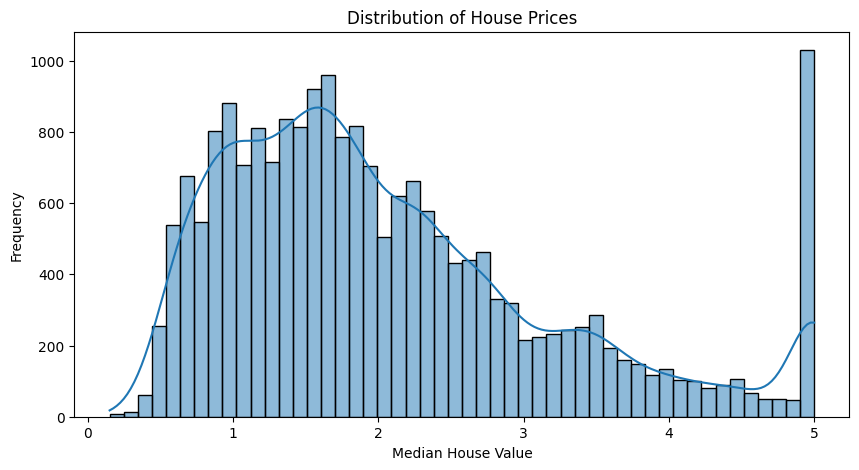

In [ ]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df["MedHouseVal"],
    bins=50,
    kde=True
)

plt.title("Distribution of House Prices")
plt.xlabel("Median House Value")
plt.ylabel("Frequency")

plt.show()

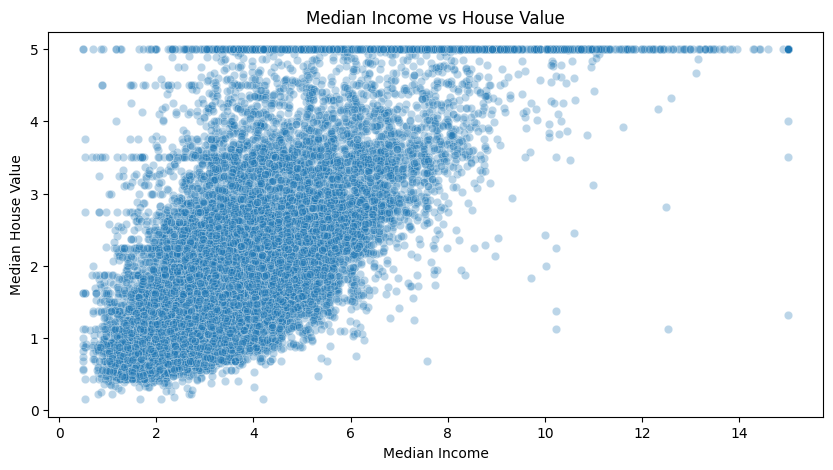

In [ ]:
plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=df,
    x="MedInc",
    y="MedHouseVal",
    alpha=0.3
)

plt.title("Median Income vs House Value")
plt.xlabel("Median Income")
plt.ylabel("Median House Value")

plt.show()

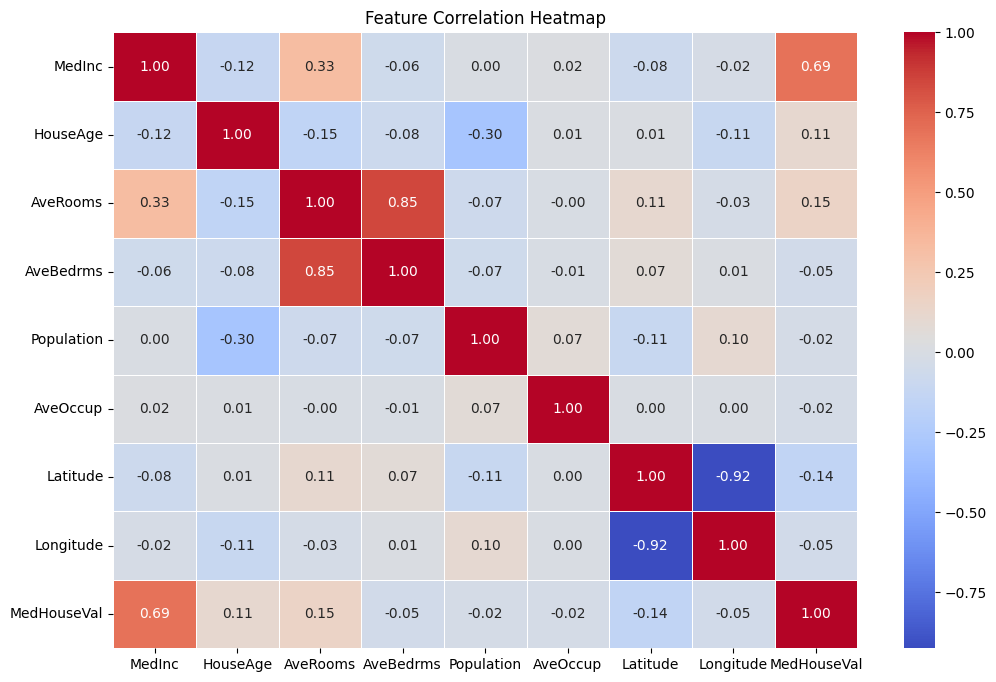

In [ ]:
# Calculate correlation matrix
correlation_matrix = df.corr()

# Visualize correlation
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Feature Correlation Heatmap")
plt.show()

In [ ]:

# Features
X = df.drop("MedHouseVal", axis=1)

# Target
y = df["MedHouseVal"]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)


Features Shape: (20640, 8)
Target Shape: (20640,)


In [ ]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)


X_train: (16512, 8)
X_test: (4128, 8)
y_train: (16512,)
y_test: (4128,)


In [ ]:

from sklearn.preprocessing import StandardScaler

# Create scaler
scaler = StandardScaler()

# Fit and transform training data
X_train_scaled = scaler.fit_transform(X_train)

# Transform testing data
X_test_scaled = scaler.transform(X_test)

print("Training shape:", X_train_scaled.shape)
print("Testing shape:", X_test_scaled.shape)


Training shape: (16512, 8)
Testing shape: (4128, 8)


In [ ]:

print("Training Mean:")
print(X_train_scaled.mean(axis=0).round(2))

print("\nTraining Standard Deviation:")
print(X_train_scaled.std(axis=0).round(2))


Training Mean:
[-0. -0.  0. -0.  0.  0.  0.  0.]

Training Standard Deviation:
[1. 1. 1. 1. 1. 1. 1. 1.]


In [ ]:

from sklearn.linear_model import LinearRegression

# Create model
model = LinearRegression()

print("Model created successfully!")


Model created successfully!


In [ ]:

# Train the model
model.fit(X_train_scaled, y_train)

print("Model trained successfully!")


Model trained successfully!


In [ ]:

# Make predictions
y_pred = model.predict(X_test_scaled)

# Display first 10 predictions
print("Predictions:")
print(y_pred[:10])


Predictions:
[0.71912284 1.76401657 2.70965883 2.83892593 2.60465725 2.01175367
 2.64550005 2.16875532 2.74074644 3.91561473]


In [ ]:

comparison = pd.DataFrame({
    "Actual Price": y_test.values[:10],
    "Predicted Price": y_pred[:10]
})

print(comparison)


   Actual Price  Predicted Price
0       0.47700         0.719123
1       0.45800         1.764017
2       5.00001         2.709659
3       2.18600         2.838926
4       2.78000         2.604657
5       1.58700         2.011754
6       1.98200         2.645500
7       1.57500         2.168755
8       3.40000         2.740746
9       4.46600         3.915615


In [ ]:

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

# Display results
print("Model Evaluation Results")
print("------------------------")
print("MAE:", round(mae, 4))
print("MSE:", round(mse, 4))
print("RMSE:", round(rmse, 4))
print("R2 Score:", round(r2, 4))


Model Evaluation Results
------------------------
MAE: 0.5332
MSE: 0.5559
RMSE: 0.7456
R2 Score: 0.5758


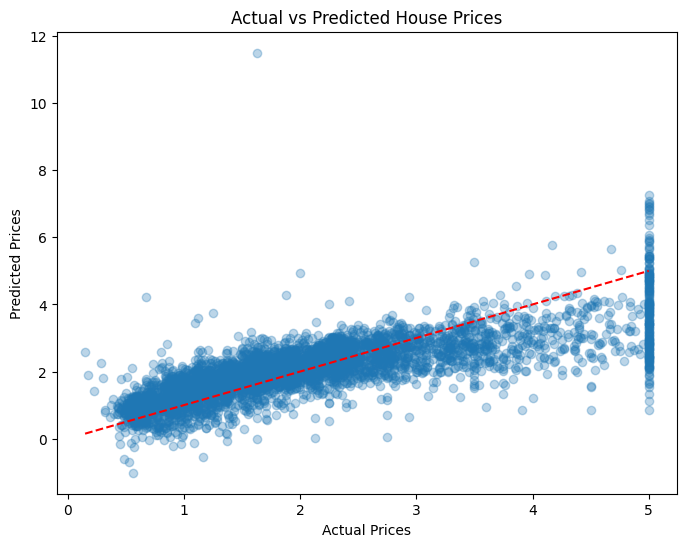

In [ ]:

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.3)

# Perfect prediction line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red",
    linestyle="--"
)

plt.xlabel("Actual Prices")
plt.ylabel("Predicted Prices")
plt.title("Actual vs Predicted House Prices")

plt.show()


In [ ]:
# Calculate residuals
residuals = y_test - y_pred

# Display first 10 residuals
print(residuals.head(10))

20046   -0.242123
3024    -1.306017
15663    2.290351
20484   -0.652926
9814     0.175343
13311   -0.424754
7113    -0.663500
7668    -0.593755
18246    0.659254
5723     0.550385
Name: MedHouseVal, dtype: float64


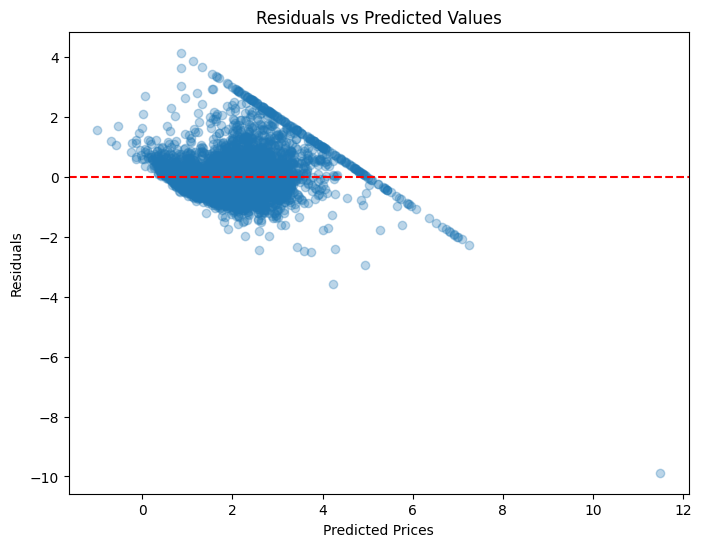

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(y_pred, residuals, alpha=0.3)
plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Predicted Prices")
plt.ylabel("Residuals")
plt.title("Residuals vs Predicted Values")

plt.show()

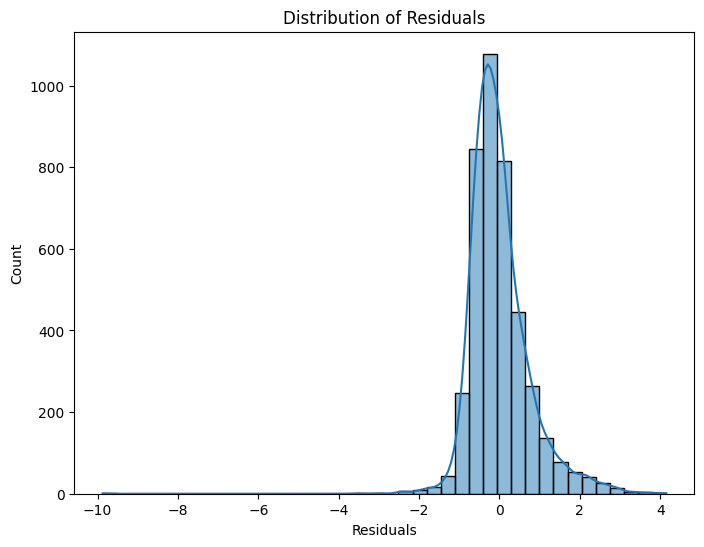

In [ ]:
plt.figure(figsize=(8, 6))

sns.histplot(residuals, bins=40, kde=True)

plt.xlabel("Residuals")
plt.title("Distribution of Residuals")

plt.show()

In [ ]:

from sklearn.ensemble import RandomForestRegressor

# Create Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

print("Random Forest created successfully!")


Random Forest created successfully!


In [ ]:

# Train Random Forest
rf_model.fit(X_train, y_train)

print("Random Forest trained successfully!")


Random Forest trained successfully!


In [ ]:

# Make predictions
rf_pred = rf_model.predict(X_test)

print("First 10 Predictions:")
print(rf_pred[:10])


First 10 Predictions:
[0.49443    0.735655   4.87733165 2.549705   2.258135   1.65105
 2.392525   1.663745   2.68061535 4.8872437 ]


In [ ]:

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

rf_mae = mean_absolute_error(y_test, rf_pred)

rf_mse = mean_squared_error(y_test, rf_pred)

rf_rmse = np.sqrt(rf_mse)

rf_r2 = r2_score(y_test, rf_pred)

print("Random Forest Evaluation")
print("------------------------")
print("MAE:", round(rf_mae, 4))
print("MSE:", round(rf_mse, 4))
print("RMSE:", round(rf_rmse, 4))
print("R2 Score:", round(rf_r2, 4))


Random Forest Evaluation
------------------------
MAE: 0.3268
MSE: 0.254
RMSE: 0.504
R2 Score: 0.8062


In [ ]:
# Predictions on training data
rf_train_pred = rf_model.predict(X_train)

# Calculate R2 scores
train_r2 = r2_score(y_train, rf_train_pred)
test_r2 = r2_score(y_test, rf_pred)

print("Training R2:", round(train_r2, 4))
print("Testing R2:", round(test_r2, 4))
print("Difference:", round(train_r2 - test_r2, 4))

Training R2: 0.9742
Testing R2: 0.8062
Difference: 0.168


In [ ]:

rf_tuned = RandomForestRegressor(
    n_estimators=200,
    max_depth=20,
    min_samples_split=10,
    min_samples_leaf=4,
    random_state=42,
    n_jobs=-1
)

# Train model
rf_tuned.fit(X_train, y_train)

# Predictions
tuned_pred = rf_tuned.predict(X_test)

# Evaluate
tuned_r2 = r2_score(y_test, tuned_pred)
tuned_mae = mean_absolute_error(y_test, tuned_pred)
tuned_rmse = np.sqrt(
    mean_squared_error(y_test, tuned_pred)
)

# Training score
tuned_train_pred = rf_tuned.predict(X_train)
tuned_train_r2 = r2_score(y_train, tuned_train_pred)

print("Tuned Random Forest")
print("-------------------")
print("Training R2:", round(tuned_train_r2, 4))
print("Testing R2:", round(tuned_r2, 4))
print("MAE:", round(tuned_mae, 4))
print("RMSE:", round(tuned_rmse, 4))
print("Difference:", round(tuned_train_r2 - tuned_r2, 4))


Tuned Random Forest
-------------------
Training R2: 0.9189
Testing R2: 0.8005
MAE: 0.3309
RMSE: 0.5113
Difference: 0.1184


In [ ]:

# Extract feature importance
importance = rf_model.feature_importances_

# Create DataFrame
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": importance
})

# Sort by importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance)


      Feature  Importance
0      MedInc    0.525886
5    AveOccup    0.138055
6    Latitude    0.088647
7   Longitude    0.088307
1    HouseAge    0.054355
2    AveRooms    0.044449
4  Population    0.030693
3   AveBedrms    0.029608


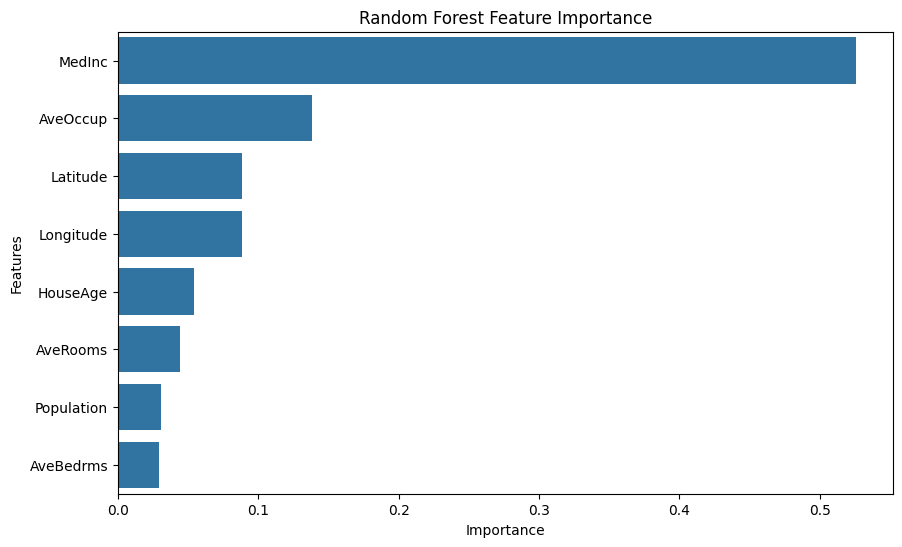

In [ ]:

plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Features")

plt.show()


In [ ]:

from sklearn.inspection import permutation_importance

# Calculate permutation importance
perm_result = permutation_importance(
    rf_model,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring="r2",
    n_jobs=-1
)

# Create DataFrame
perm_importance = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": perm_result.importances_mean,
    "Std": perm_result.importances_std
})

# Sort results
perm_importance = perm_importance.sort_values(
    by="Importance",
    ascending=False
)

print(perm_importance)


      Feature  Importance       Std
0      MedInc    0.734720  0.014501
6    Latitude    0.442926  0.008716
7   Longitude    0.335223  0.006005
5    AveOccup    0.203600  0.005693
1    HouseAge    0.072149  0.004041
2    AveRooms    0.027069  0.001700
3   AveBedrms    0.009467  0.001402
4  Population    0.008667  0.001091


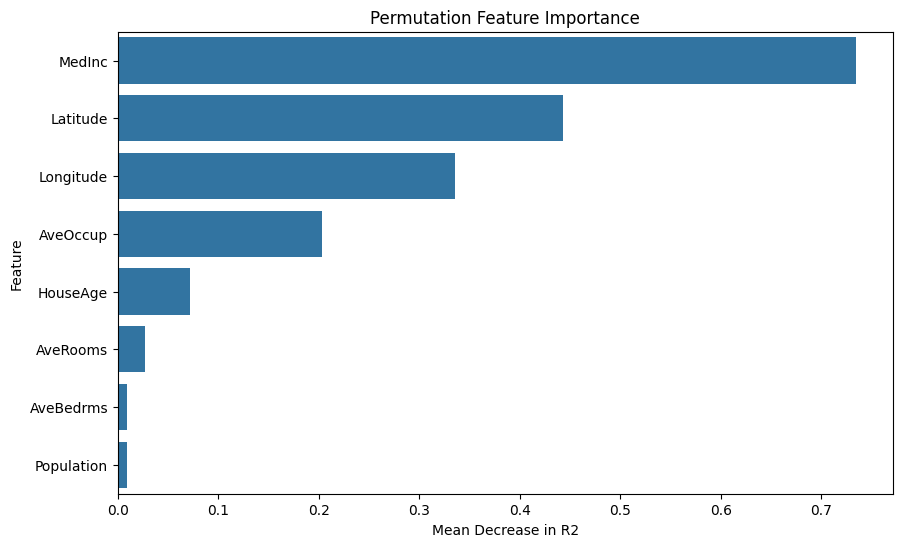

In [ ]:

plt.figure(figsize=(10, 6))

sns.barplot(
    data=perm_importance,
    x="Importance",
    y="Feature"
)

plt.title("Permutation Feature Importance")
plt.xlabel("Mean Decrease in R2")
plt.ylabel("Feature")

plt.show()


In [ ]:
comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest",
        "Tuned Random Forest"
    ],
    "MAE": [
        0.5332,
        0.3268,
        0.3309
    ],
    "RMSE": [
        0.7456,
        0.5040,
        0.5113
    ],
    "R2 Score": [
        0.5758,
        0.8062,
        0.8005
    ]
})

comparison

,Model,MAE,RMSE,R2 Score
0,Linear Regression,0.5332,0.7456,0.5758
1,Random Forest,0.3268,0.5040,0.8062
2,Tuned Random Forest,0.3309,0.5113,0.8005


In [34]:

import joblib

# Save the best model
joblib.dump(rf_model, "house_price_model.pkl")

# Save feature names
joblib.dump(
    list(X_train.columns),
    "feature_names.pkl"
)

print("Model saved successfully!")


Model saved successfully!


In [35]:

# Load saved model
loaded_model = joblib.load("house_price_model.pkl")

# Test loaded model
sample_prediction = loaded_model.predict(X_test.iloc[:5])

print("Predictions:", sample_prediction)


Predictions: [0.49443    0.735655   4.87733165 2.549705   2.258135  ]
